# Superstore Sales Analysis

In [120]:
import pandas as pd

df = pd.read_csv("../Sample - Superstore.csv", encoding="latin-1")
print(df.shape)
df.info()

(9994, 21)
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity

## 1. Data cleaning

In [121]:
df["Order Date"] = pd.to_datetime(df["Order Date"], format="%m/%d/%Y")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="%m/%d/%Y")
df["Postal Code"] = df["Postal Code"].astype(str)
df.dtypes

Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code                 str
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
Quantity                  int64
Discount                float64
Profit                  float64
dtype: object

## 2. Which products make or lose money?

In [122]:
print("Duplicate rows:", df.drop(columns="Row ID").duplicated().sum())
print("Shipped before ordered:", (df["Ship Date"] < df["Order Date"]).sum())
print("Rows with negative profit:", (df["Profit"] < 0).sum())
df[["Sales", "Quantity", "Discount", "Profit"]].describe()

Duplicate rows: 1
Shipped before ordered: 0
Rows with negative profit: 1871


,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


## 3. The effect of discounts on profit


In [123]:
import matplotlib.pyplot as plt

cat = df.groupby("Category")[["Sales", "Profit"]].sum().round(0)
cat["Margin %"] = (cat["Profit"] / cat["Sales"] * 100).round(1)
cat

,Sales,Profit,Margin %
Category,,,
Furniture,742000.0,18451.0,2.5
Office Supplies,719047.0,122491.0,17.0
Technology,836154.0,145455.0,17.4


## 4. Tables: a closer look

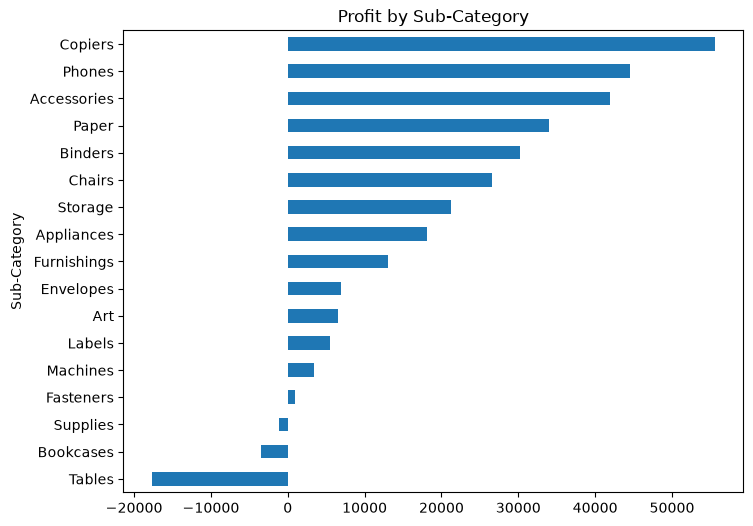

In [124]:
sub = df.groupby("Sub-Category")[["Sales", "Profit"]].sum().sort_values("Profit")
sub.plot(kind="barh", y="Profit", figsize=(8, 6), legend=False)
plt.title("Profit by Sub-Category")
plt.show()

## 5. Seasonality

In [125]:
check = df.groupby("Sub-Category").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Avg_Discount=("Discount", "mean"),
).round(2)
check["Margin %"] = (check["Profit"] / check["Sales"] * 100).round(1)
check.sort_values("Profit")

,Sales,Profit,Avg_Discount,Margin %
Sub-Category,,,,
Tables,206965.53,-17725.48,0.26,-8.6
Bookcases,114880.00,-3472.56,0.21,-3.0
Supplies,46673.54,-1189.10,0.08,-2.5
Fasteners,3024.28,949.52,0.08,31.4
Machines,189238.63,3384.76,0.31,1.8
Labels,12486.31,5546.25,0.07,44.4
Art,27118.79,6527.79,0.07,24.1
Envelopes,16476.40,6964.18,0.08,42.3
Furnishings,91705.16,13059.14,0.14,14.2


In [126]:
df["Discount Band"] = pd.cut(
    df["Discount"], bins=[-0.01, 0, 0.2, 0.4, 1.0],
    labels=["No discount", "Up to 20%", "20-40%", "Over 40%"]
)
df.groupby("Discount Band", observed=True)["Profit"].agg(["sum", "mean", "count"]).round(1)

,sum,mean,count
Discount Band,,,
No discount,320987.6,66.9,4798
Up to 20%,100785.5,26.5,3803
20-40%,-35817.5,-77.9,460
Over 40%,-99558.6,-106.7,933


In [127]:
tables = df[df["Sub-Category"] == "Tables"]
tables.groupby("Discount Band", observed=True)["Profit"].agg(["sum", "mean", "count"]).round(1)

,sum,mean,count
Discount Band,,,
No discount,13276.3,184.4,72
Up to 20%,-303.6,-4.3,71
20-40%,-19589.7,-151.9,129
Over 40%,-11108.5,-236.4,47


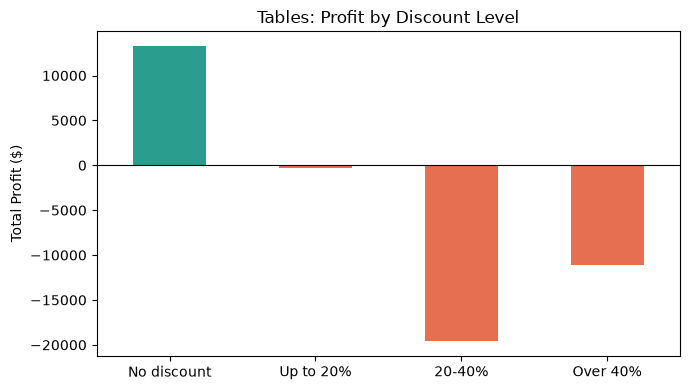

In [128]:
band = tables.groupby("Discount Band", observed=True)["Profit"].sum()
colors = ["#2a9d8f" if v > 0 else "#e76f51" for v in band]

ax = band.plot(kind="bar", color=colors, figsize=(7, 4))
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Tables: Profit by Discount Level")
ax.set_xlabel("")
ax.set_ylabel("Total Profit ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../images/tables_profit_by_discount.png", dpi=150)
plt.show()

## Discounts above 20% turn Tables into a loss-making category

Without a discount, Tables generate ___ in profit. 
Once the discount exceeds 20%, the total profit becomes ___.

**Recommendation:** ___

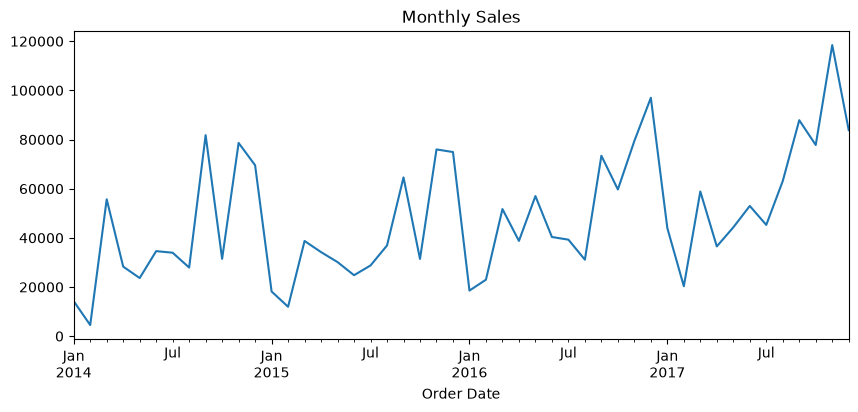

In [129]:
monthly = df.groupby(df["Order Date"].dt.to_period("M"))[["Sales", "Profit"]].sum()
monthly["Sales"].plot(figsize=(10, 4), title="Monthly Sales")
plt.show()

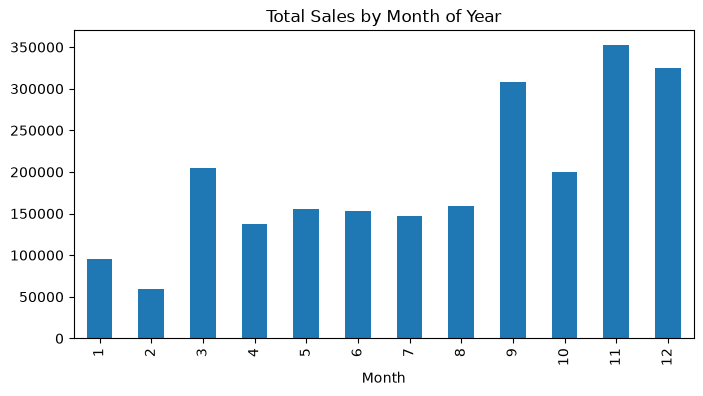

In [130]:
by_month = df.groupby(df["Order Date"].dt.month)["Sales"].sum()
by_month.plot(kind="bar", figsize=(8, 4), title="Total Sales by Month of Year")
plt.xlabel("Month")
plt.show()

In [131]:
df["Month"] = df["Order Date"].dt.month

month_stats = df.groupby("Month").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Avg_Discount=("Discount", "mean"),
)
month_stats["Margin %"] = (month_stats["Profit"] / month_stats["Sales"] * 100).round(1)
month_stats.round(2)

,Sales,Profit,Avg_Discount,Margin %
Month,,,,
1,94924.84,9134.45,0.15,9.6
2,59751.25,10294.61,0.15,17.2
3,205005.49,28594.69,0.16,13.9
4,137762.13,11587.44,0.16,8.4
5,155028.81,22411.31,0.17,14.5
6,152718.68,21285.80,0.16,13.9
7,147238.10,13832.66,0.16,9.4
8,159044.06,21776.94,0.15,13.7
9,307649.95,36857.48,0.15,12.0


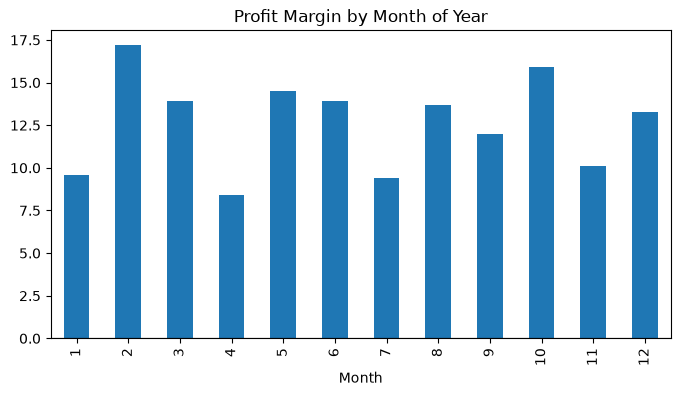

In [132]:
month_stats["Margin %"].plot(kind="bar", figsize=(8, 4), title="Profit Margin by Month of Year")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Month")
plt.show()

## Discounts above 20% turn Tables into a loss-making category

Tables are the biggest loss-maker in the store, with a total loss of about $17.7K.
However, the product itself is not the problem: with no discount, Tables generate
about $13.3K in profit. The loss comes from orders with discounts above 20%,
which lose about $30.7K combined.

**Recommendation:** cap discounts on Tables at 20%.

In [133]:
df["High Discount"] = df["Discount"] > 0.2

mix = df.groupby("Month")["High Discount"].mean().round(2).rename("High_Discount_Share")

cat_mix = df.pivot_table(index="Month", columns="Category", values="Sales", aggfunc="sum")
cat_mix = cat_mix.div(cat_mix.sum(axis=1), axis=0).round(2)

mix.to_frame().join(cat_mix).join(month_stats["Margin %"])

,High_Discount_Share,Furniture,Office Supplies,Technology,Margin %
Month,,,,,
1,0.15,0.33,0.35,0.32,9.6
2,0.14,0.26,0.35,0.39,17.2
3,0.15,0.25,0.28,0.48,13.9
4,0.14,0.30,0.36,0.35,8.4
5,0.15,0.31,0.28,0.41,14.5
6,0.14,0.35,0.34,0.32,13.9
7,0.14,0.34,0.29,0.37,9.4
8,0.12,0.28,0.39,0.33,13.7
9,0.13,0.35,0.33,0.32,12.0


In [134]:
df["Year"] = df["Order Date"].dt.year
yr = df.groupby(["Year", "Month"])[["Sales", "Profit"]].sum()
yr["Margin %"] = (yr["Profit"] / yr["Sales"] * 100).round(1)
yr["Margin %"].unstack("Year")

Year,2014,2015,2016,2017
Month,,,,
1,17.2,-18.1,15.2,16.2
2,19.1,23.5,21.8,7.9
3,0.9,25.1,7.0,25.1
4,12.3,12.2,7.7,2.6
5,11.6,15.5,15.2,14.3
6,14.4,13.5,11.8,15.5
7,-2.5,11.4,11.3,15.4
8,19.1,14.5,6.6,14.3
9,10.2,12.7,12.7,12.5


In [135]:
jan15 = df[(df["Year"] == 2015) & (df["Month"] == 1)]
jan15.nsmallest(5, "Profit")[["Order ID", "Sub-Category", "Sales", "Discount", "Profit"]]

,Order ID,Sub-Category,Sales,Discount,Profit
9639,CA-2015-116638,Tables,4297.6440,0.40,-1862.3124
215,CA-2015-146262,Machines,1188.0000,0.70,-950.4000
5055,CA-2015-141243,Bookcases,1352.3976,0.32,-437.5404
1669,US-2015-157154,Tables,1018.1040,0.40,-373.3048
467,US-2015-101399,Furnishings,254.7440,0.60,-312.0614


In [136]:
total = jan15["Profit"].sum()
without_top5 = jan15.drop(jan15.nsmallest(5, "Profit").index)["Profit"].sum()
print("Jan 2015 profit:", round(total))
print("Without the 5 worst orders:", round(without_top5))

Jan 2015 profit: -3281
Without the 5 worst orders: 655


In [137]:
region = df.groupby("Region")[["Sales", "Profit"]].sum()
region["Margin %"] = (region["Profit"] / region["Sales"] * 100).round(1)
print(region.round(0))

state = df.groupby("State")[["Sales", "Profit"]].sum().sort_values("Profit")
state.head(10)

            Sales    Profit  Margin %
Region                               
Central  501240.0   39706.0       8.0
East     678781.0   91523.0      14.0
South    391722.0   46749.0      12.0
West     725458.0  108418.0      15.0


,Sales,Profit
State,,
Texas,170188.0458,-25729.3563
Ohio,78258.1360,-16971.3766
Pennsylvania,116511.9140,-15559.9603
Illinois,80166.1010,-12607.8870
North Carolina,55603.1640,-7490.9122
Colorado,32108.1180,-6527.8579
Tennessee,30661.8730,-5341.6936
Arizona,35282.0010,-3427.9246
Florida,89473.7080,-3399.3017


## Conclusions